# Win Probability computation - Prediction of round outcome 
from raw data 
For any one match 
- STOMs (evolution) vs. epochs
- Win probabilities for each Map


Scanning 1351 directories for valid Ancient matches...
Found Ancient Match: a91868f5-3289-4a69-8b38-573b1c742c47


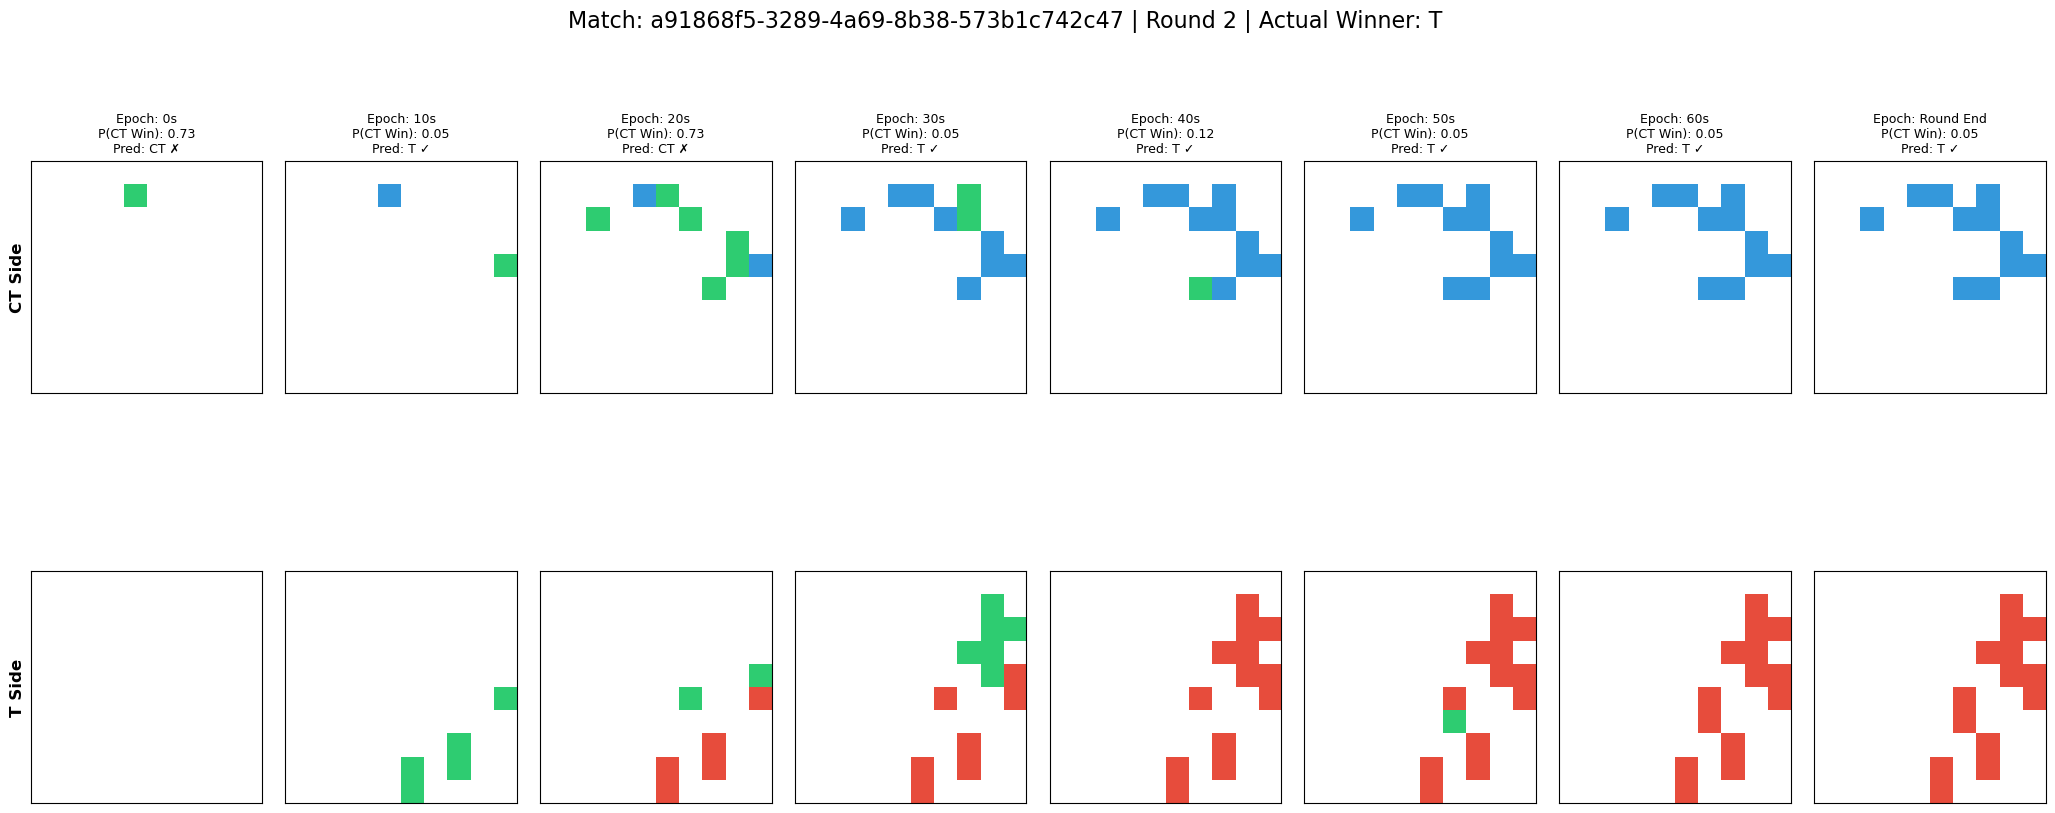

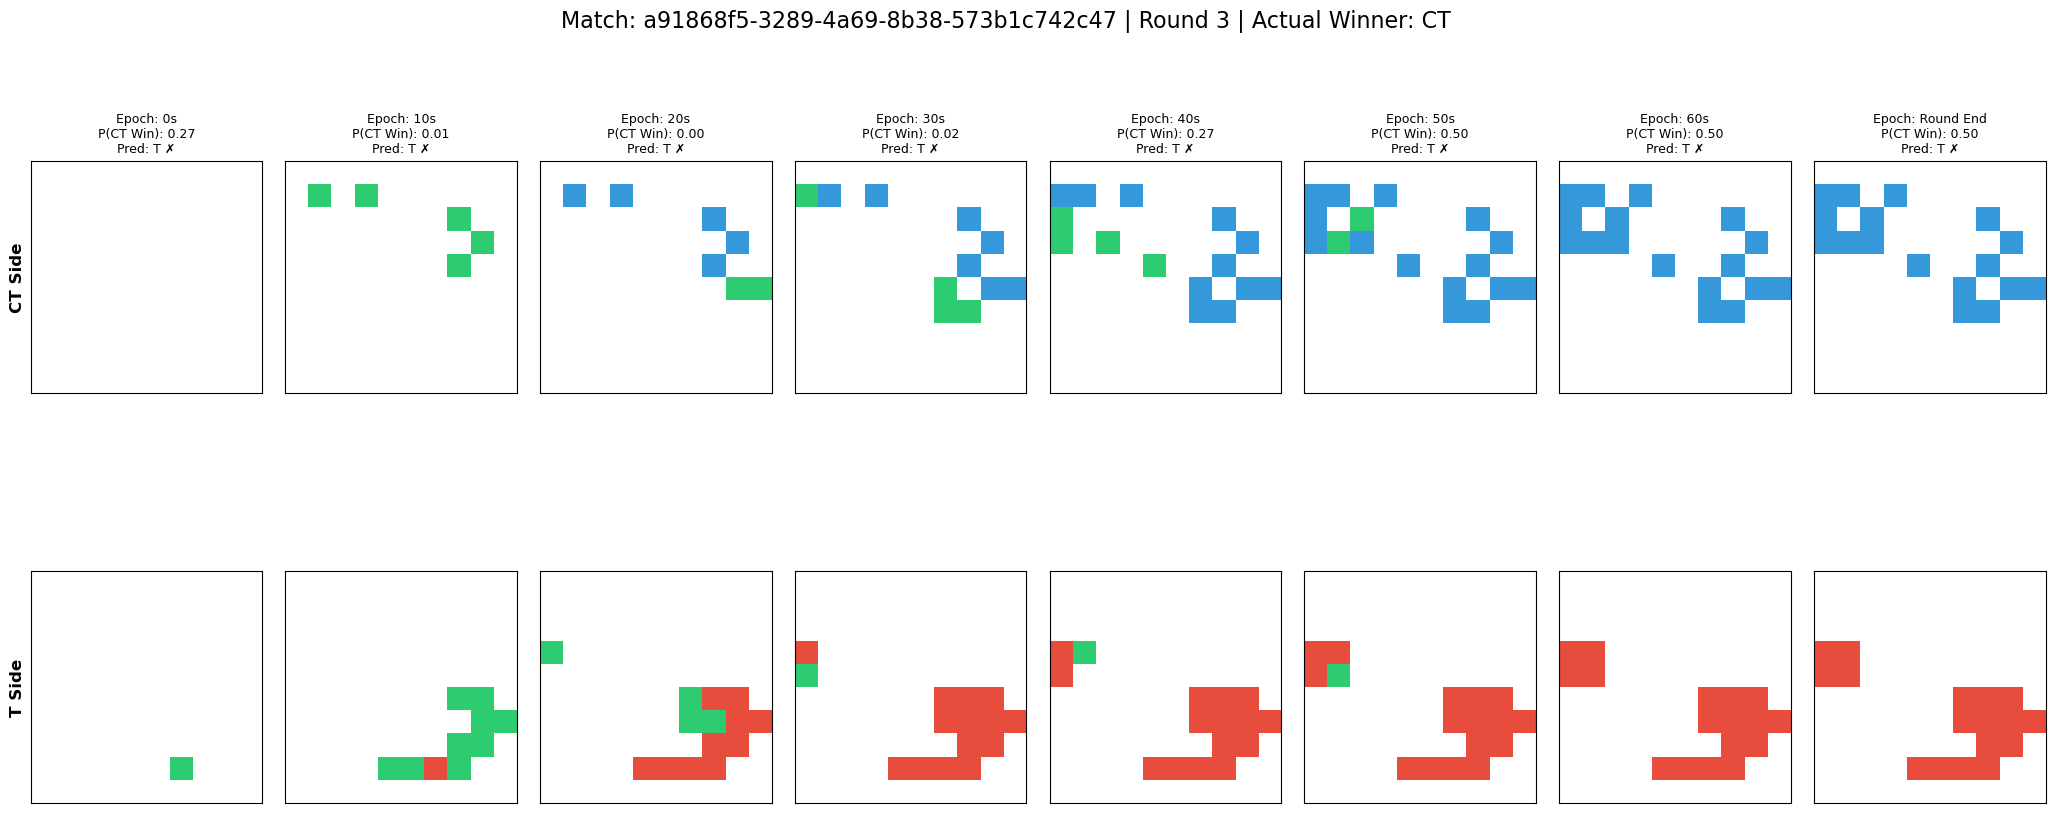

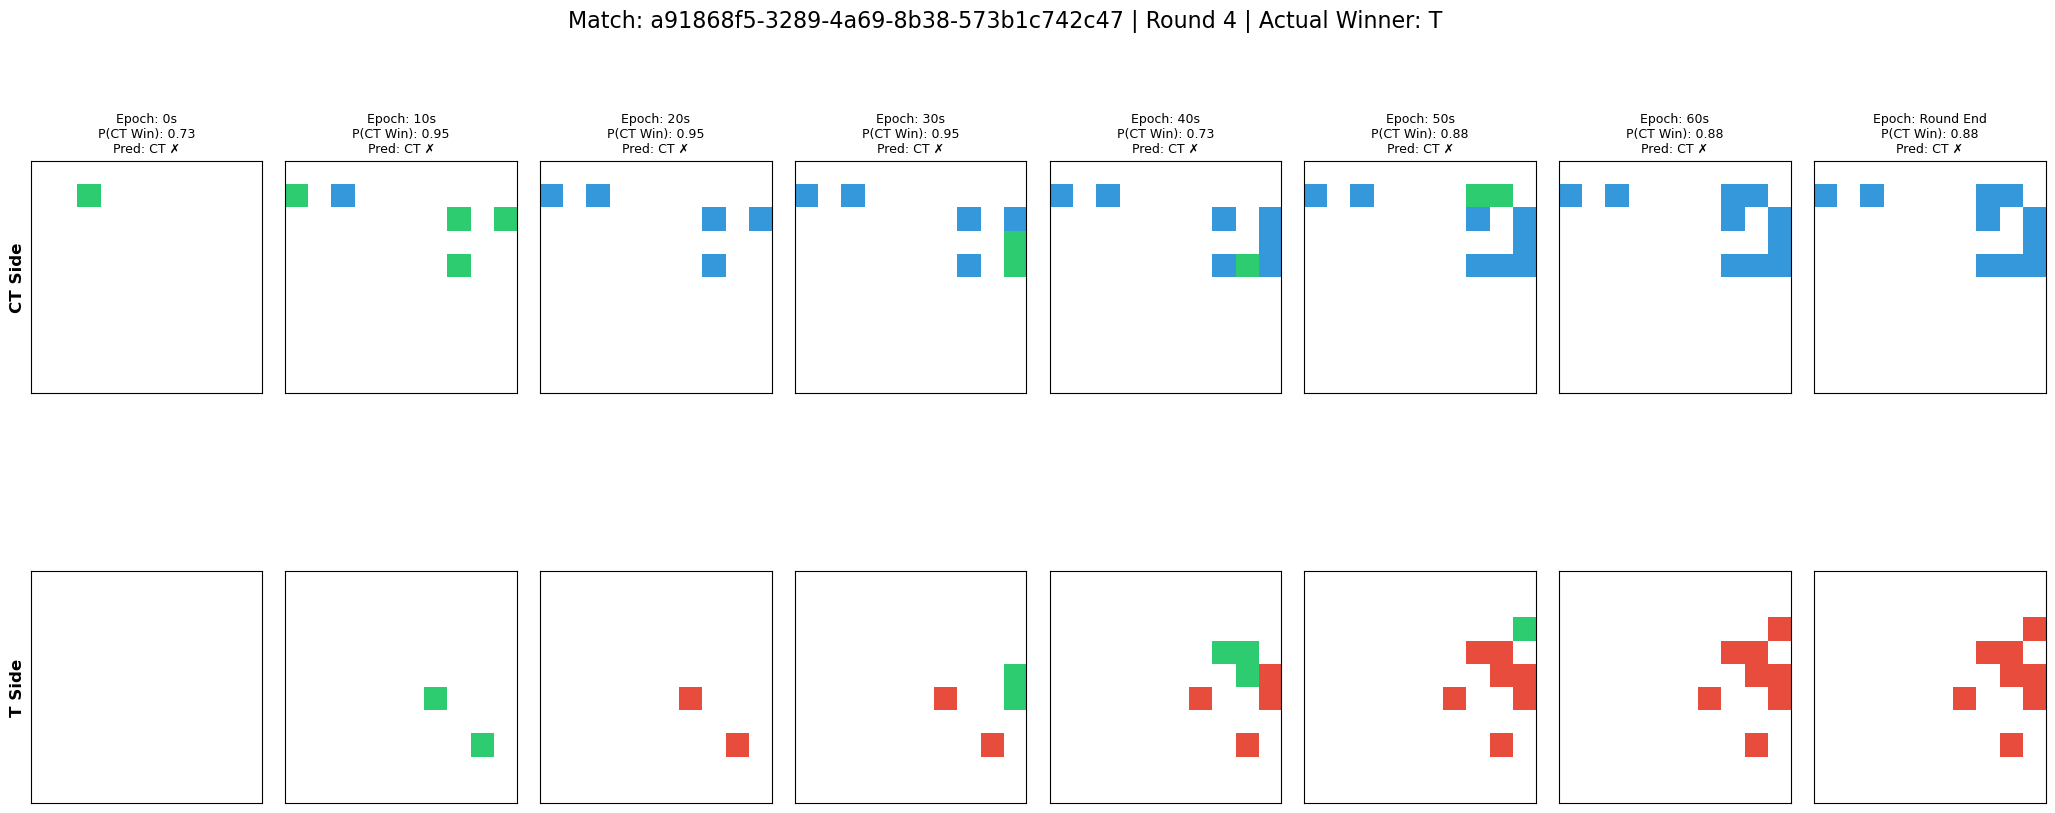

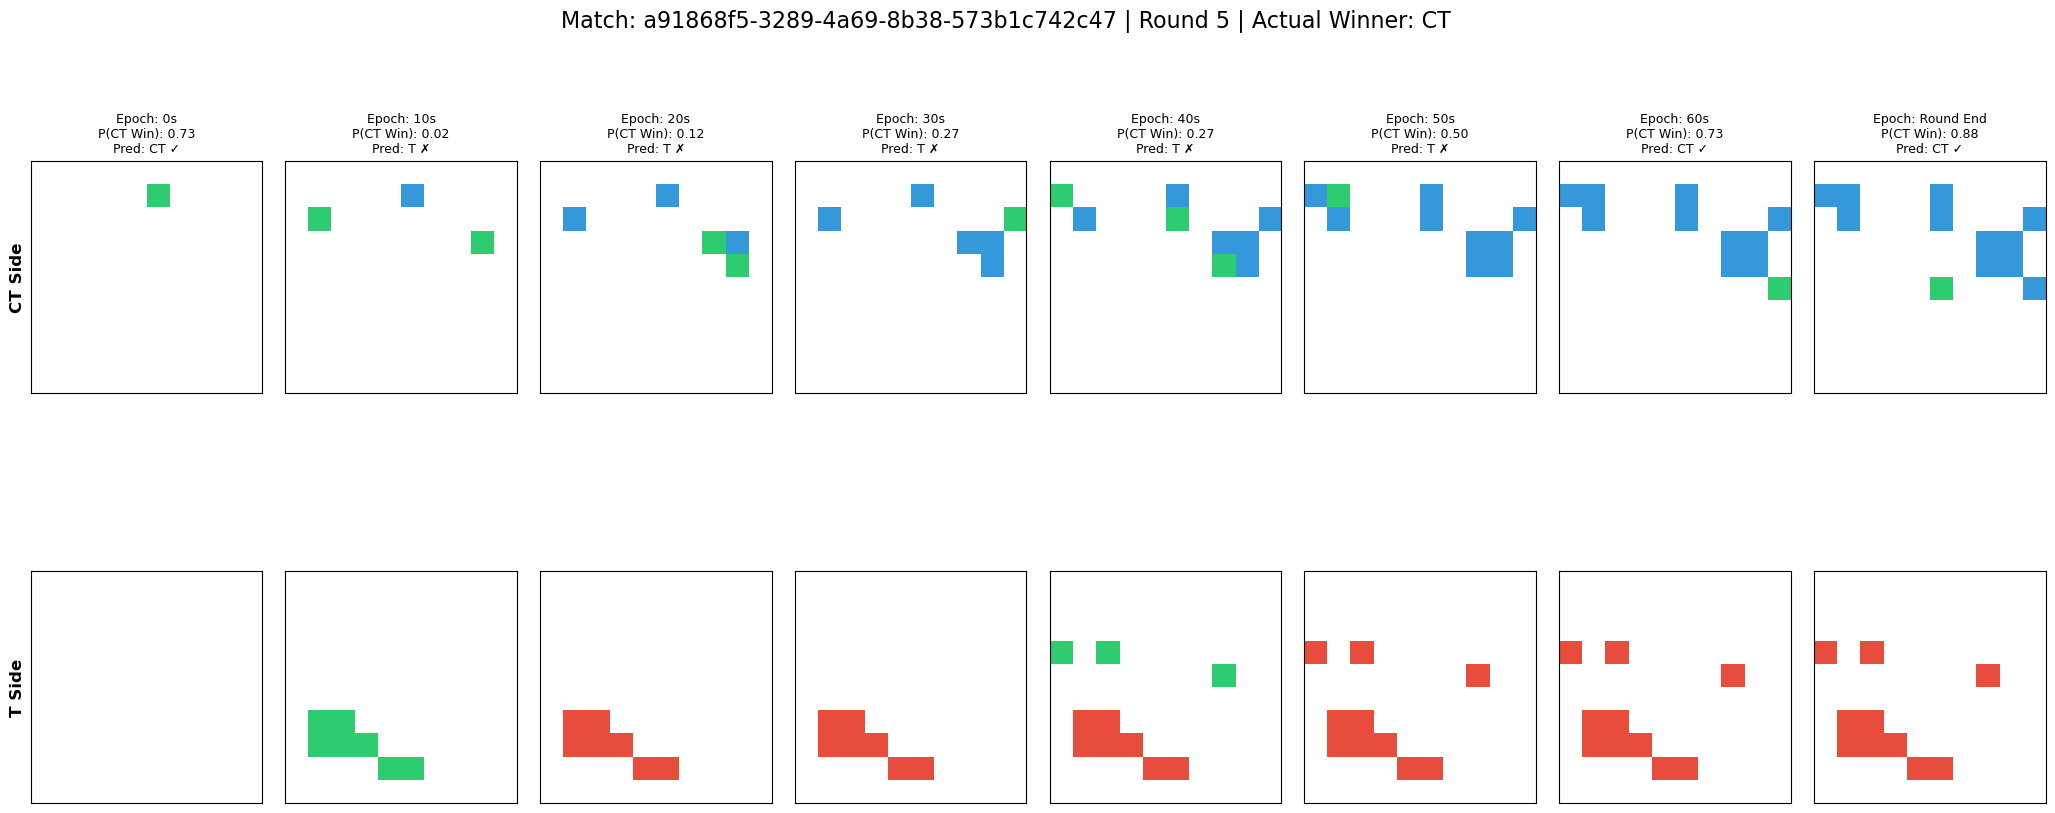

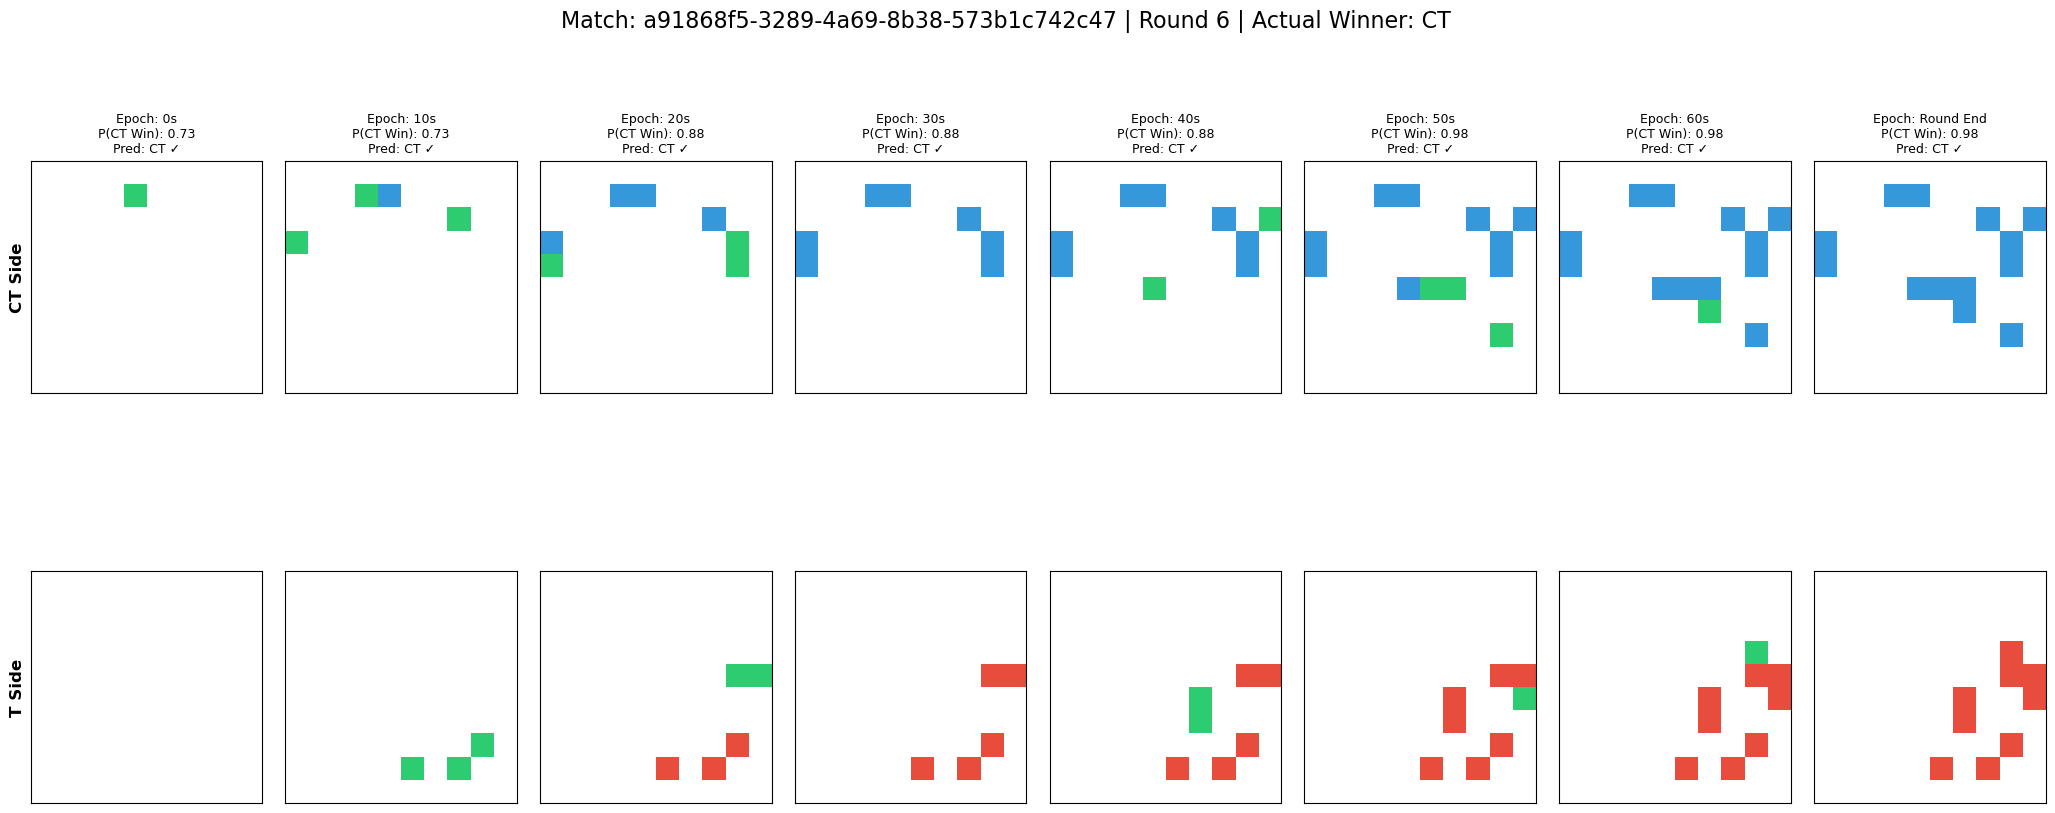

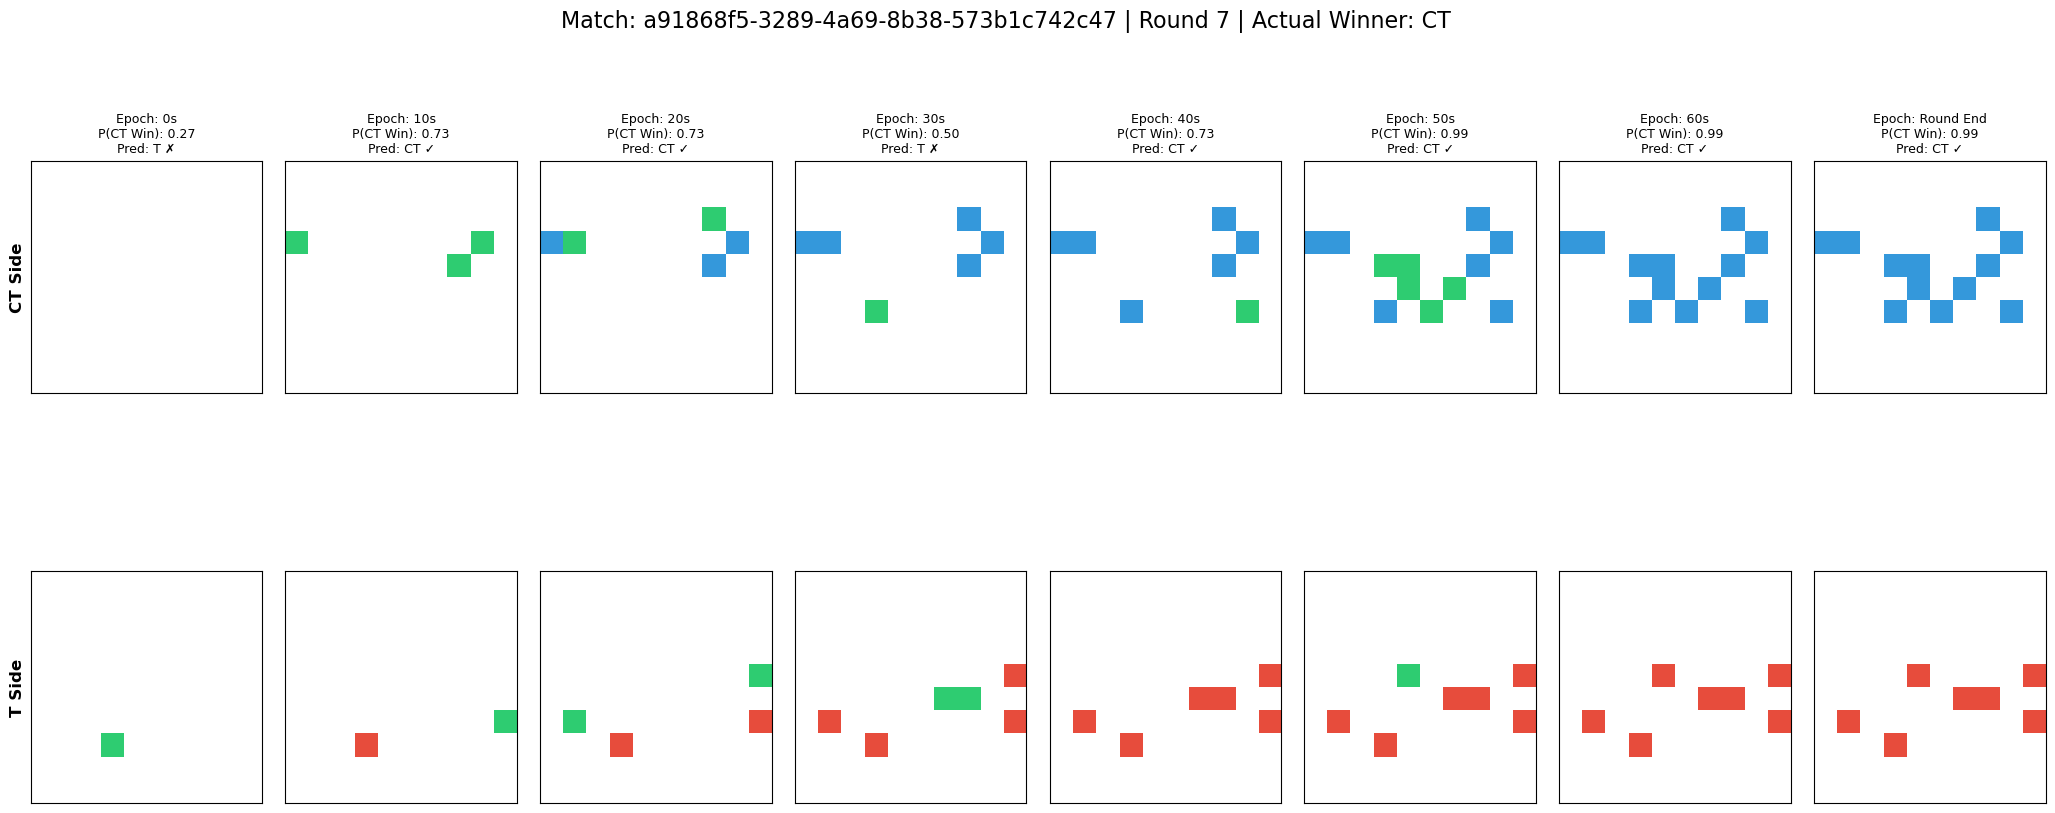

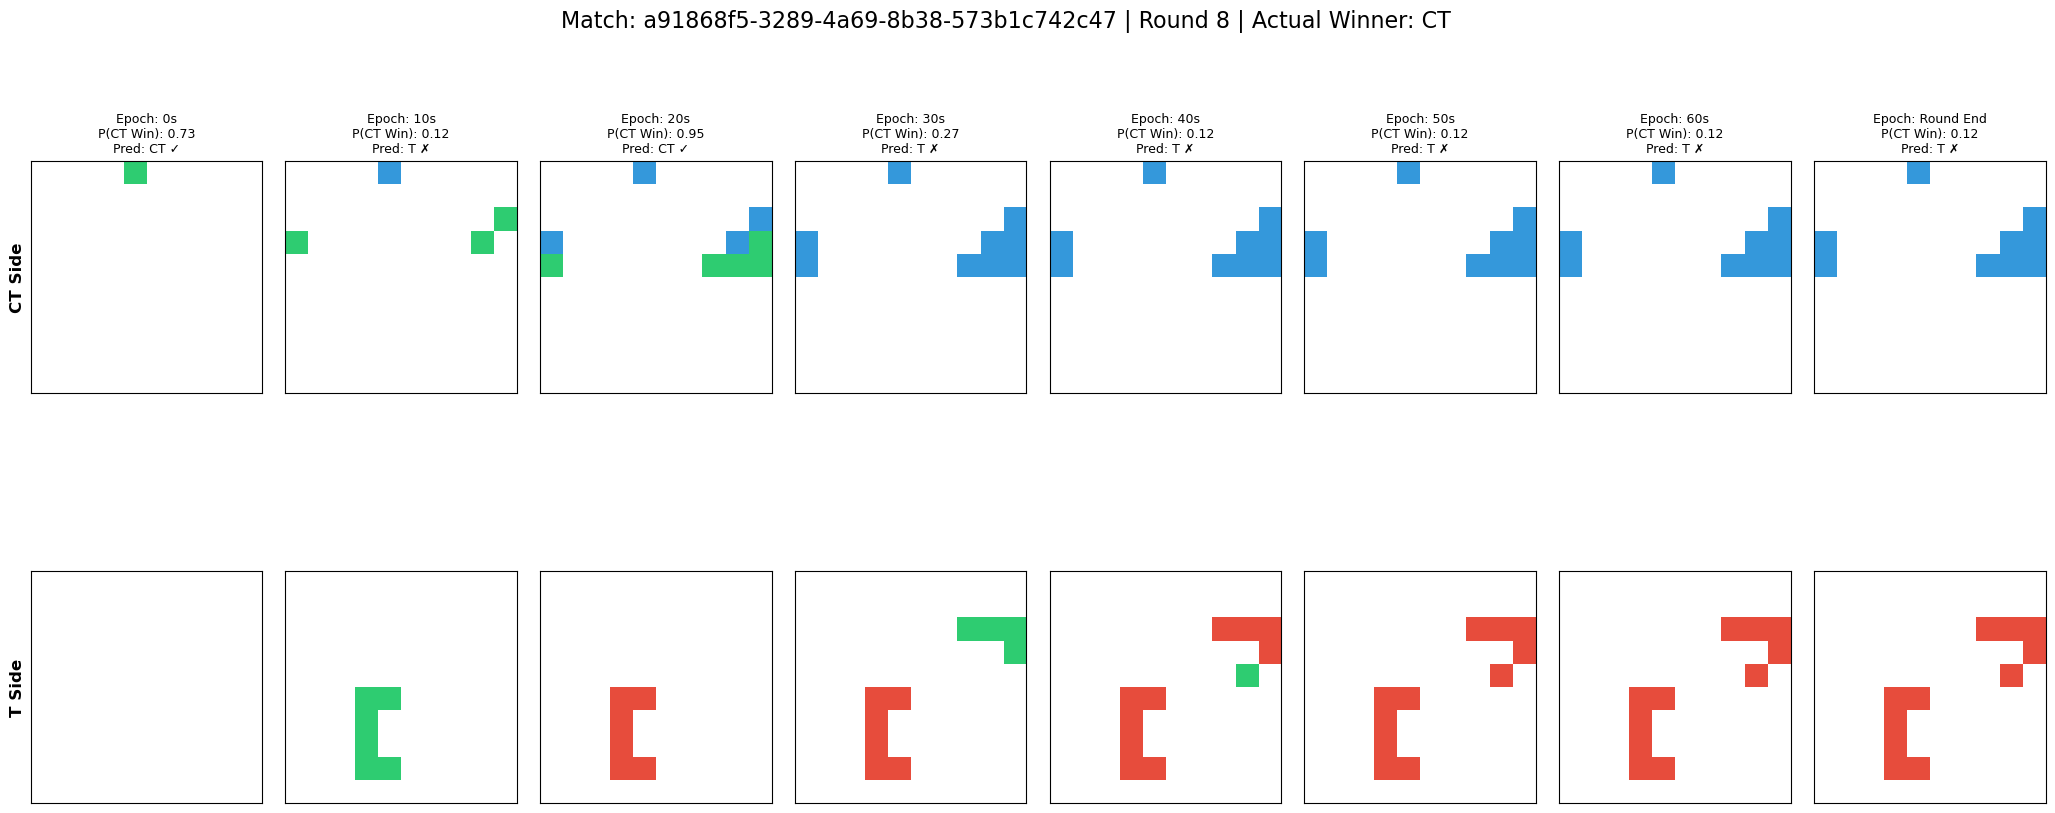

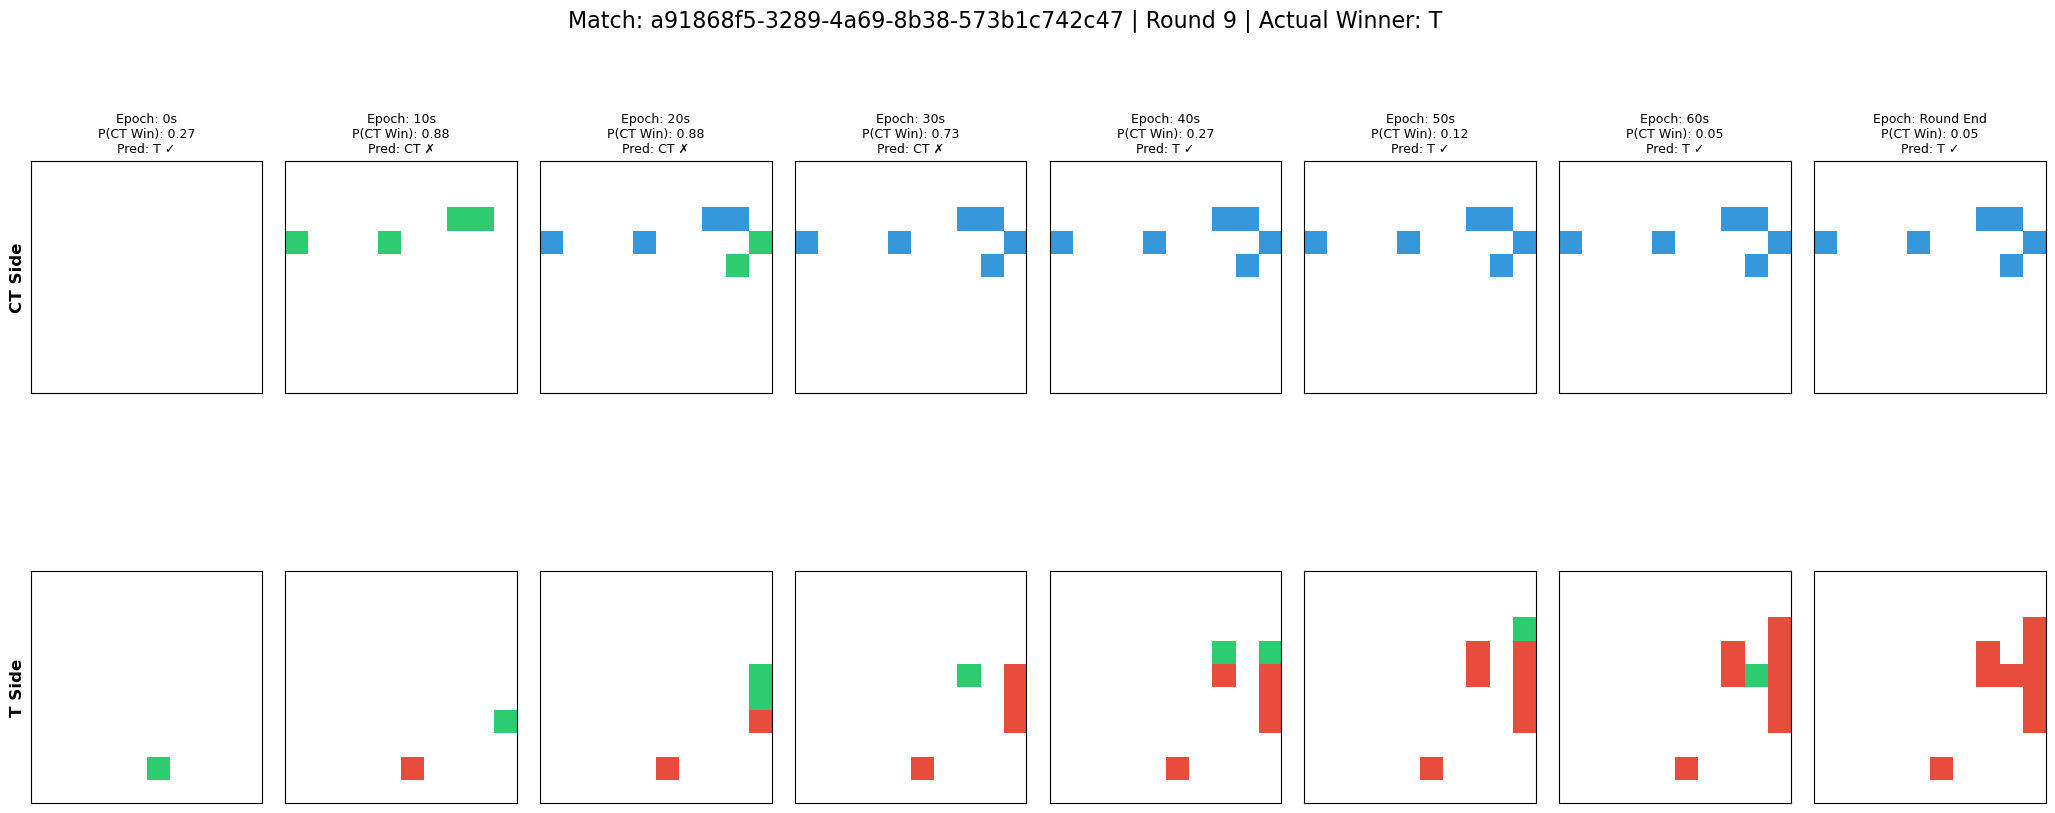

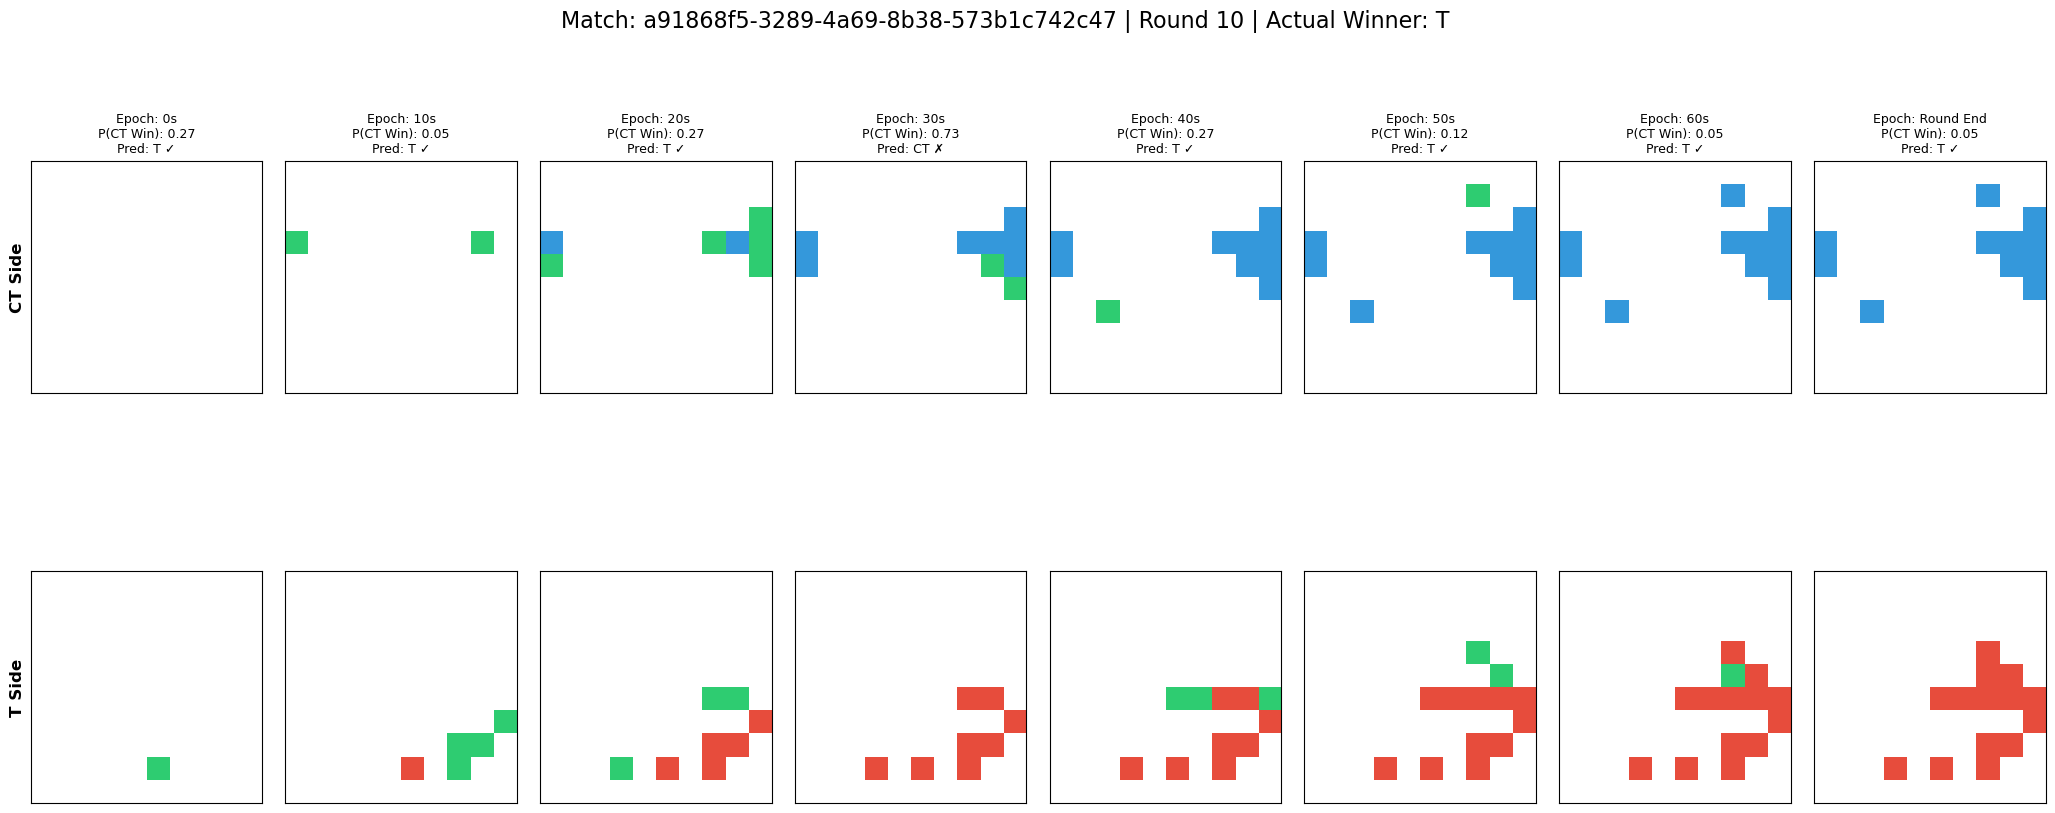

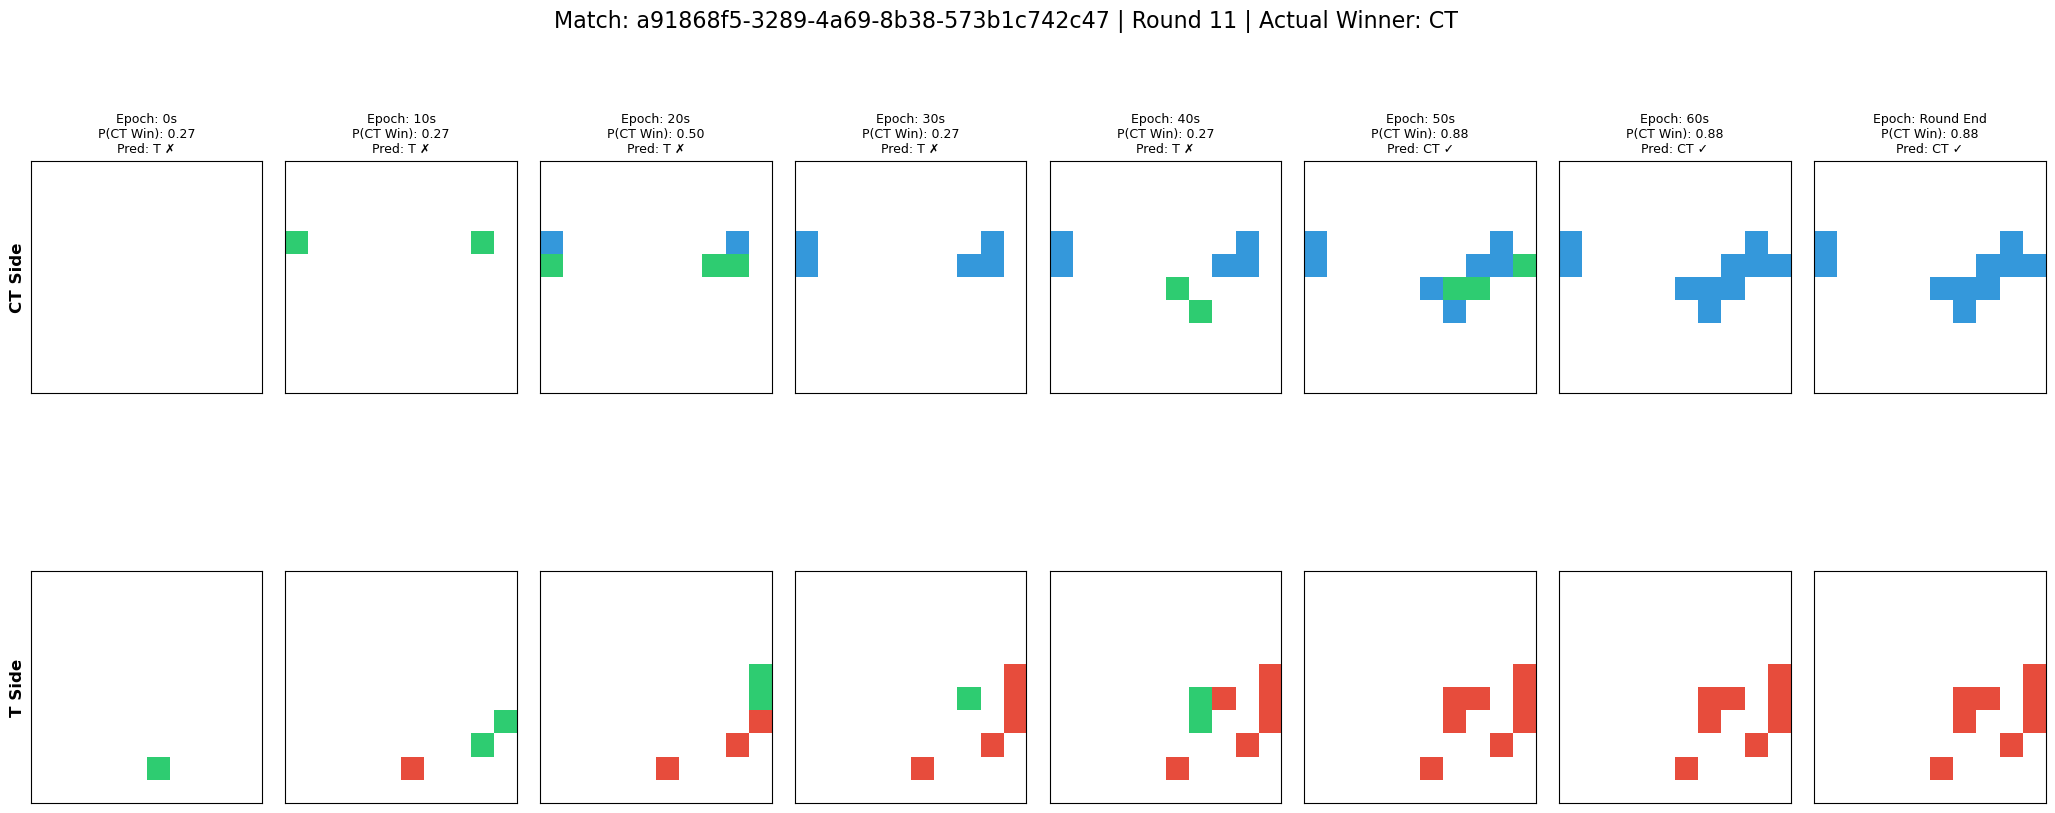

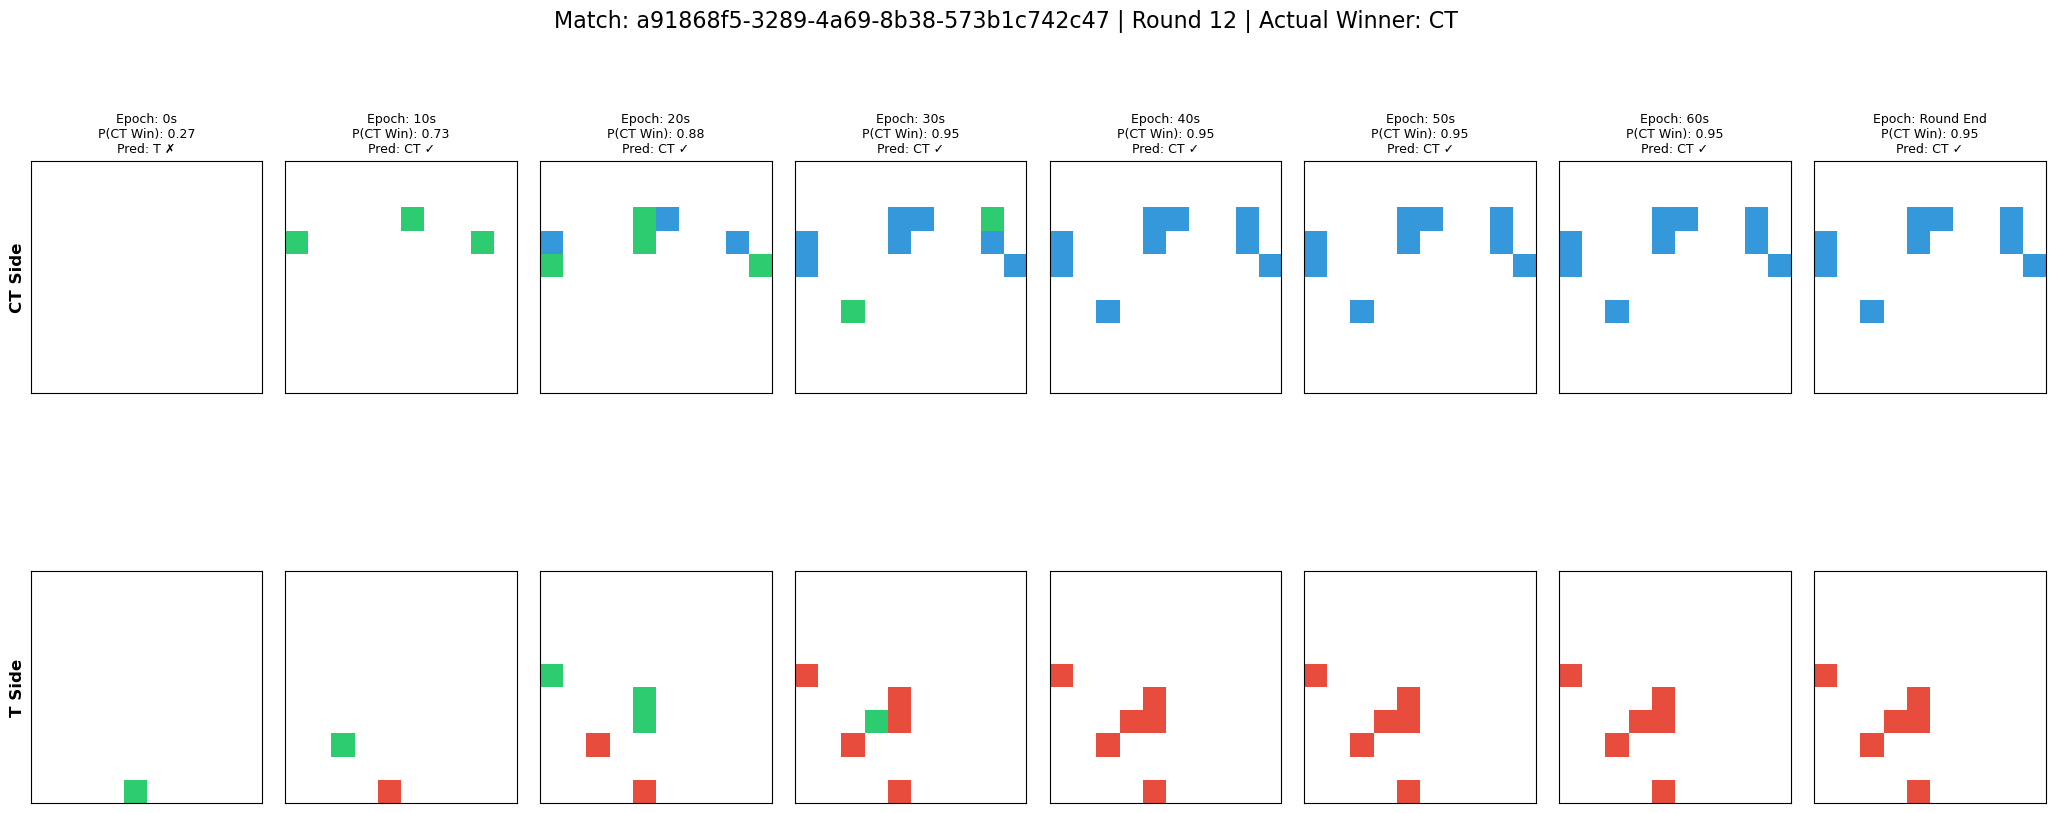

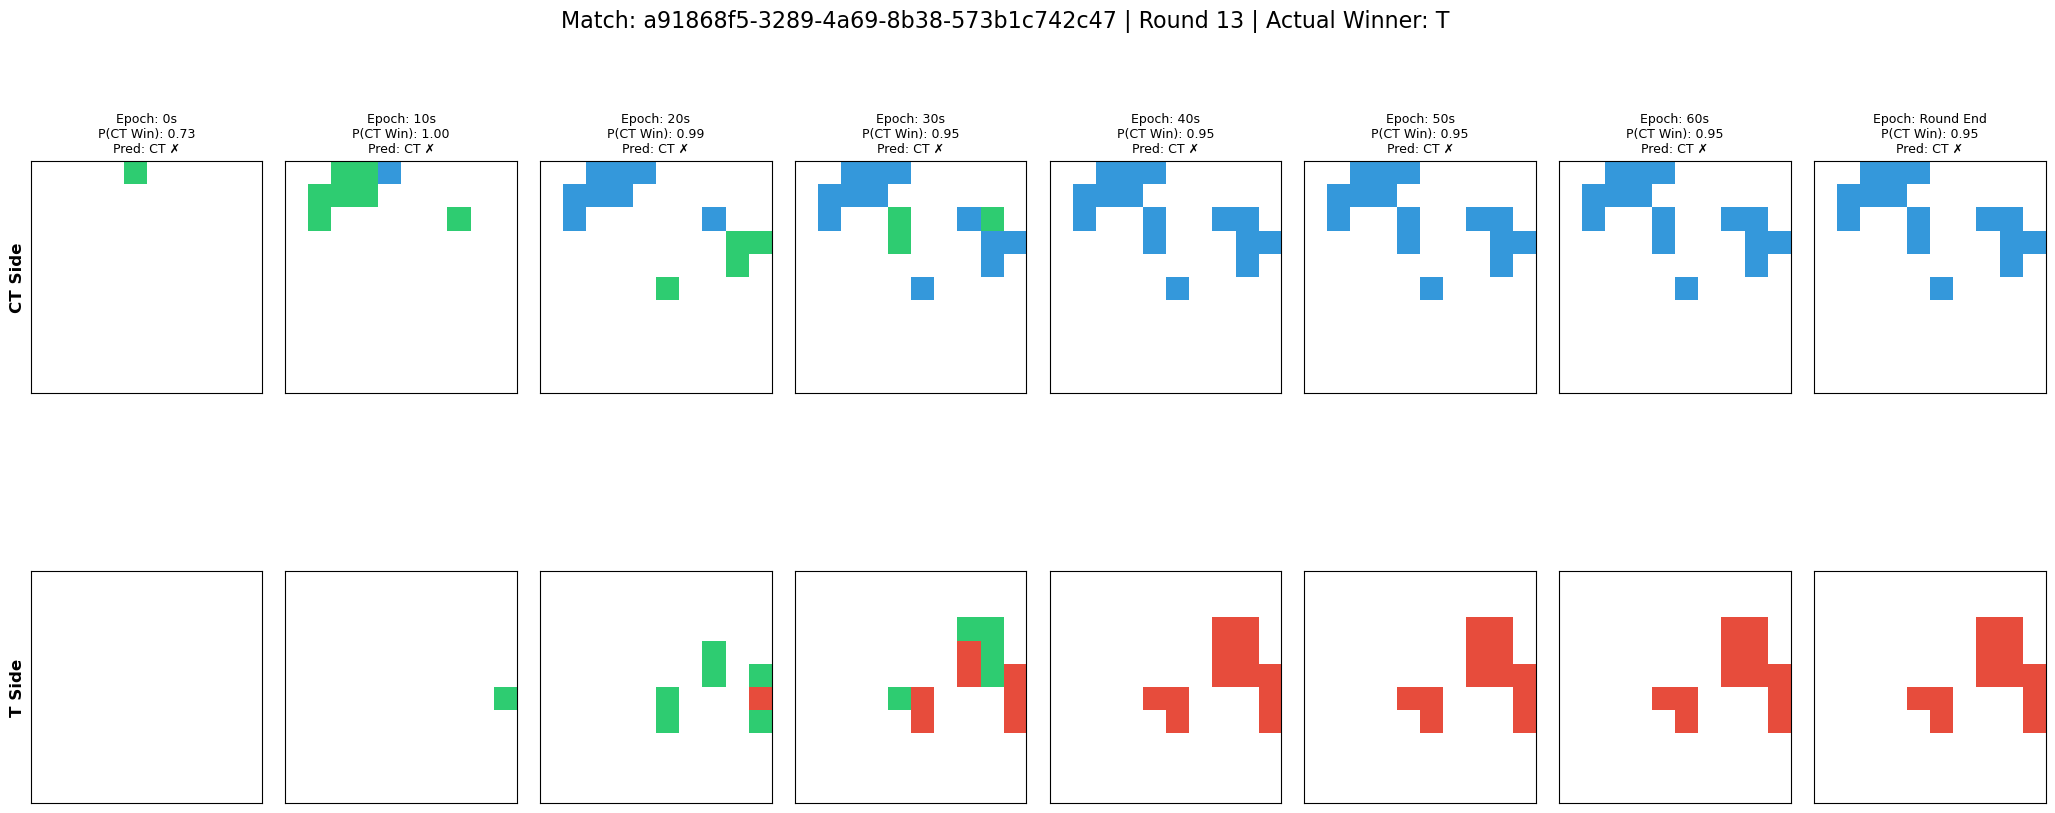

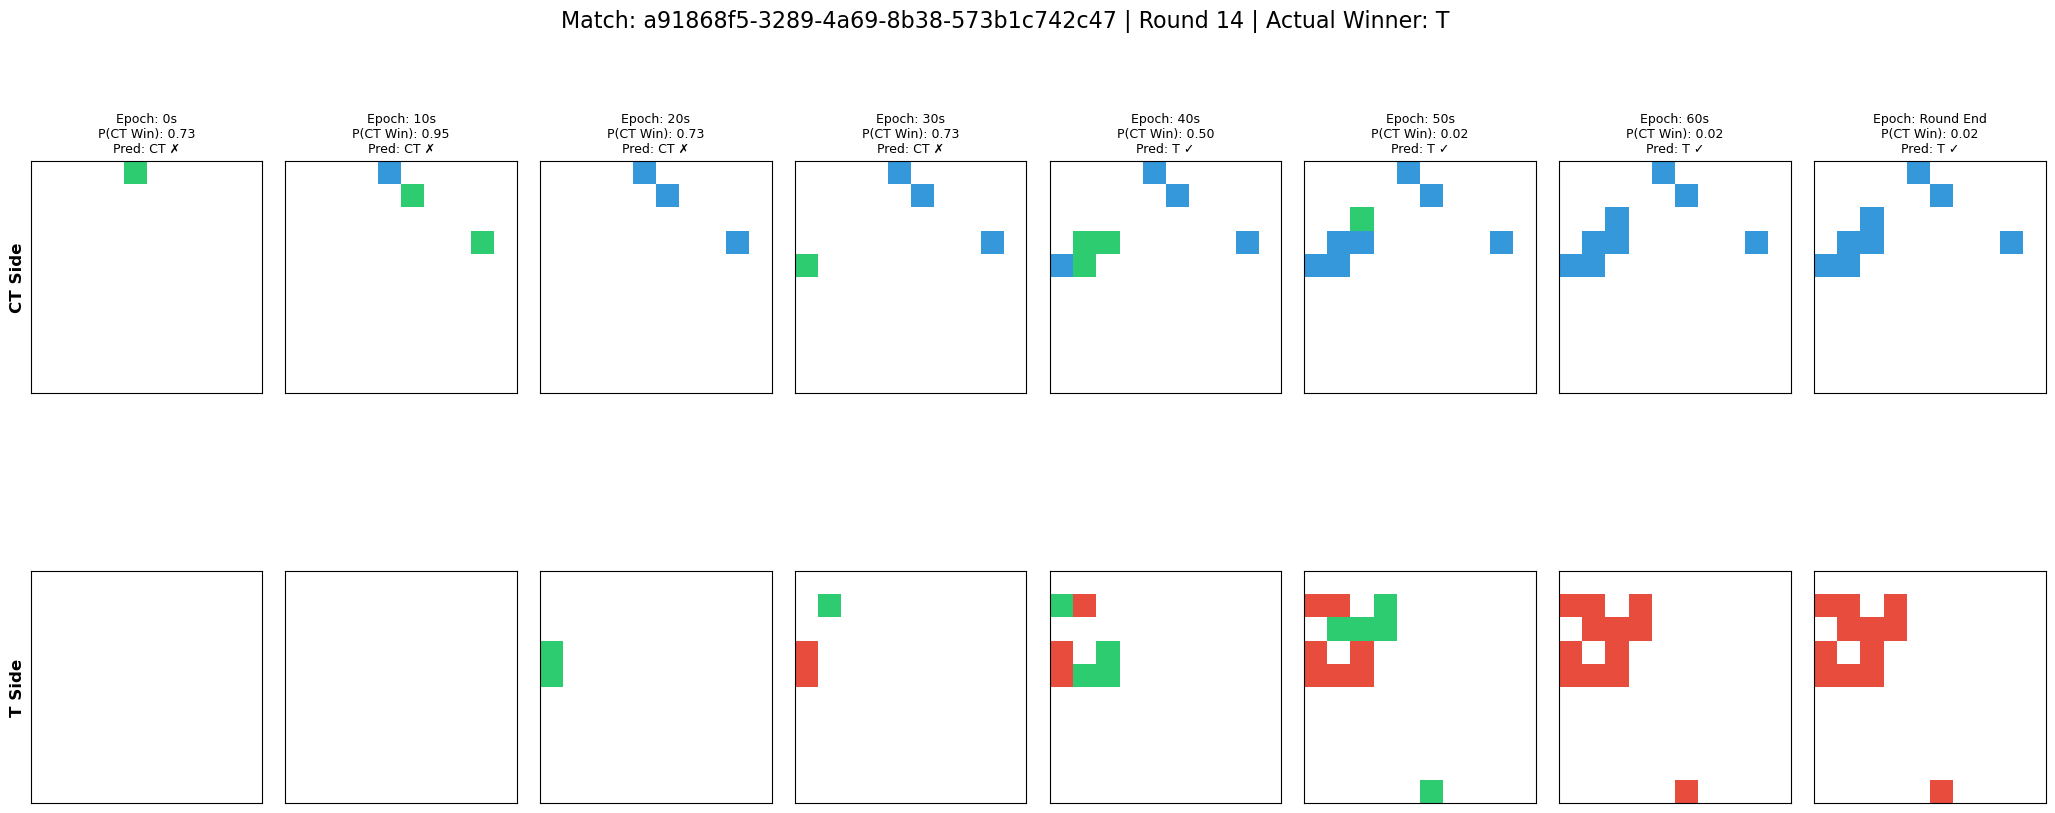

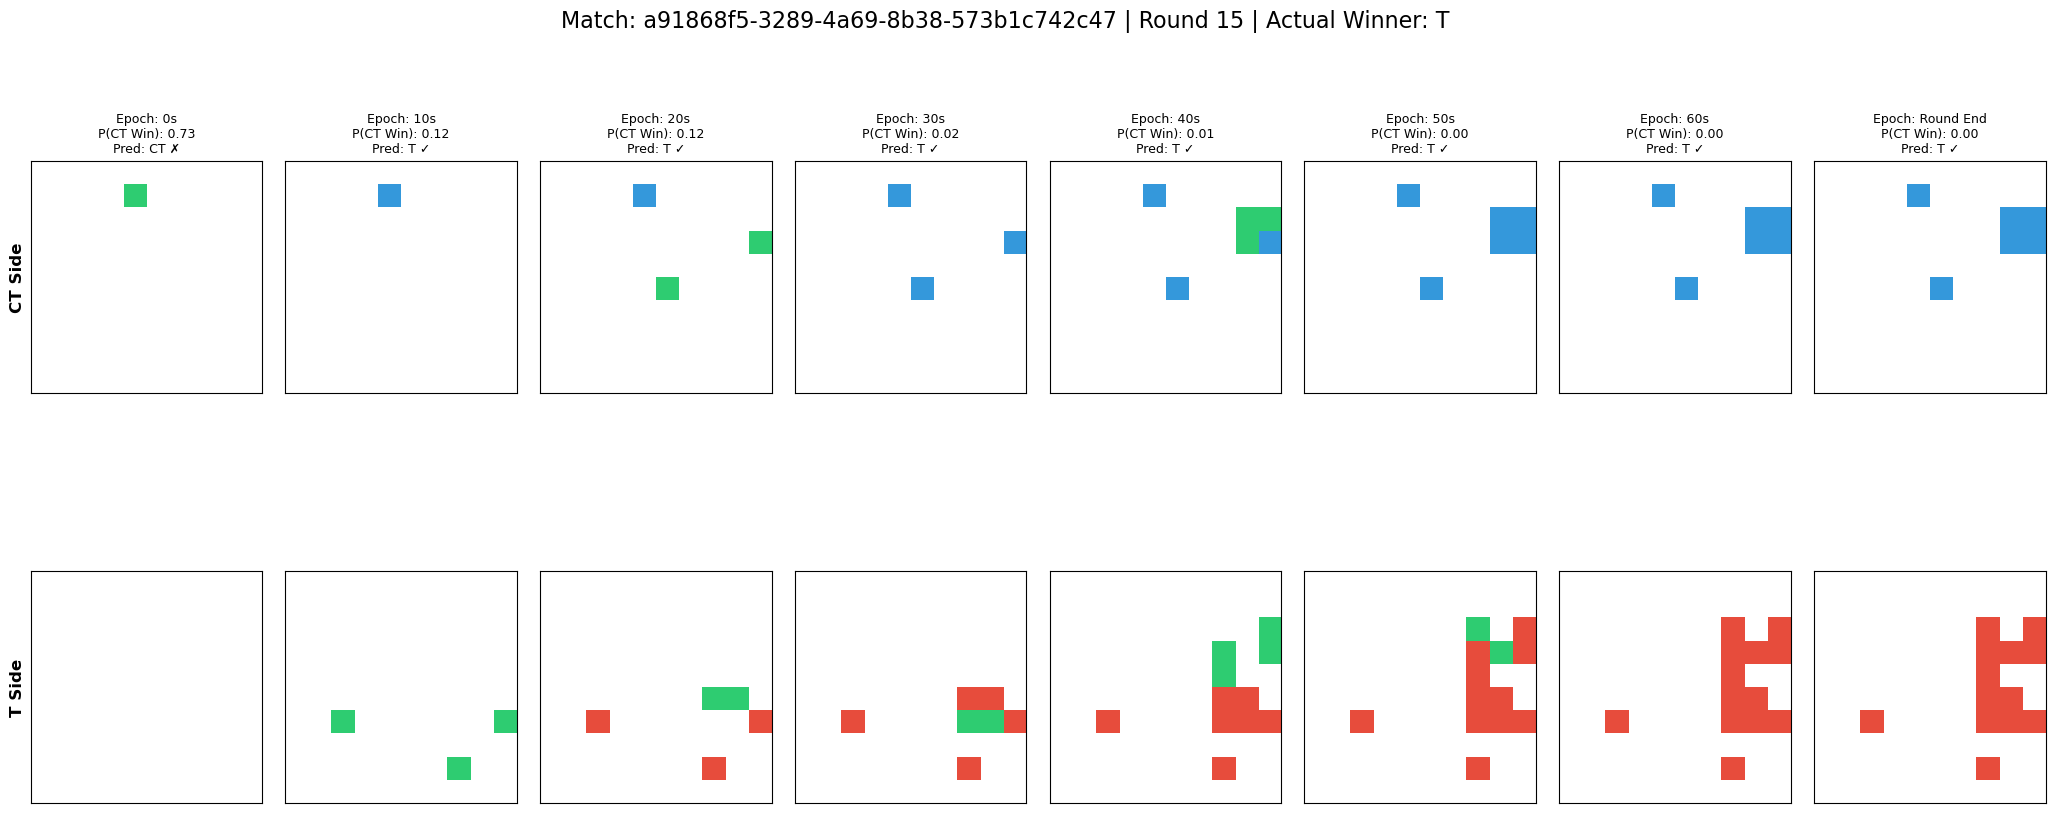

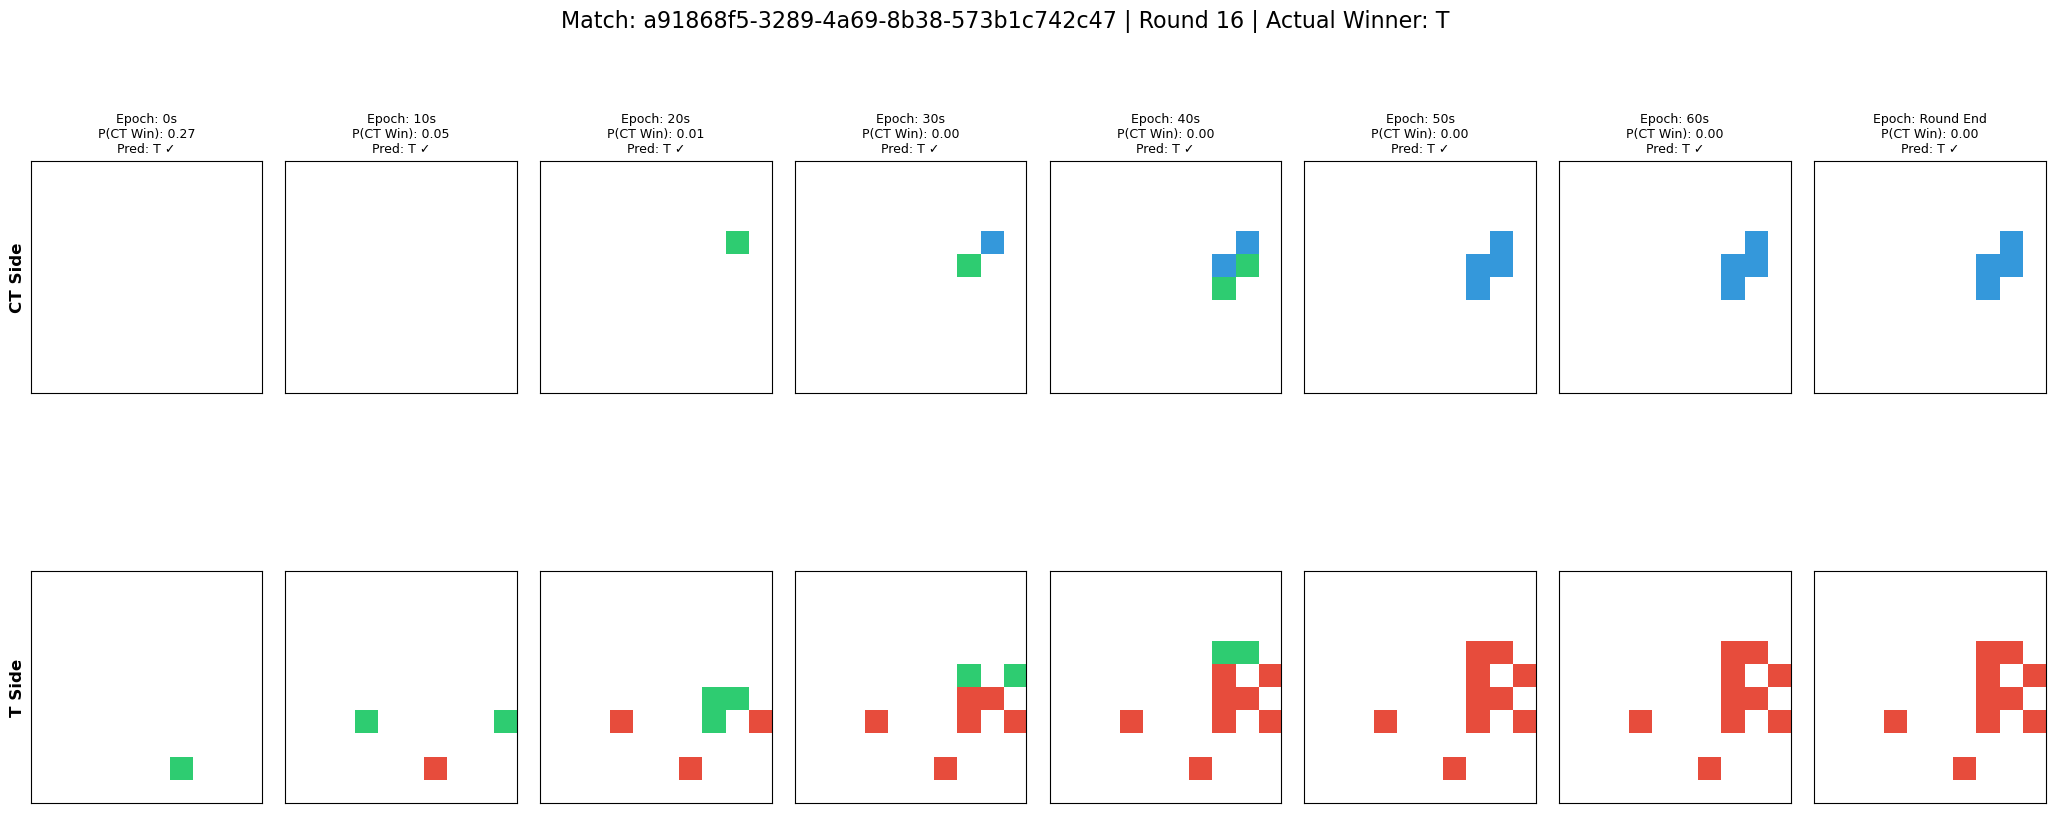

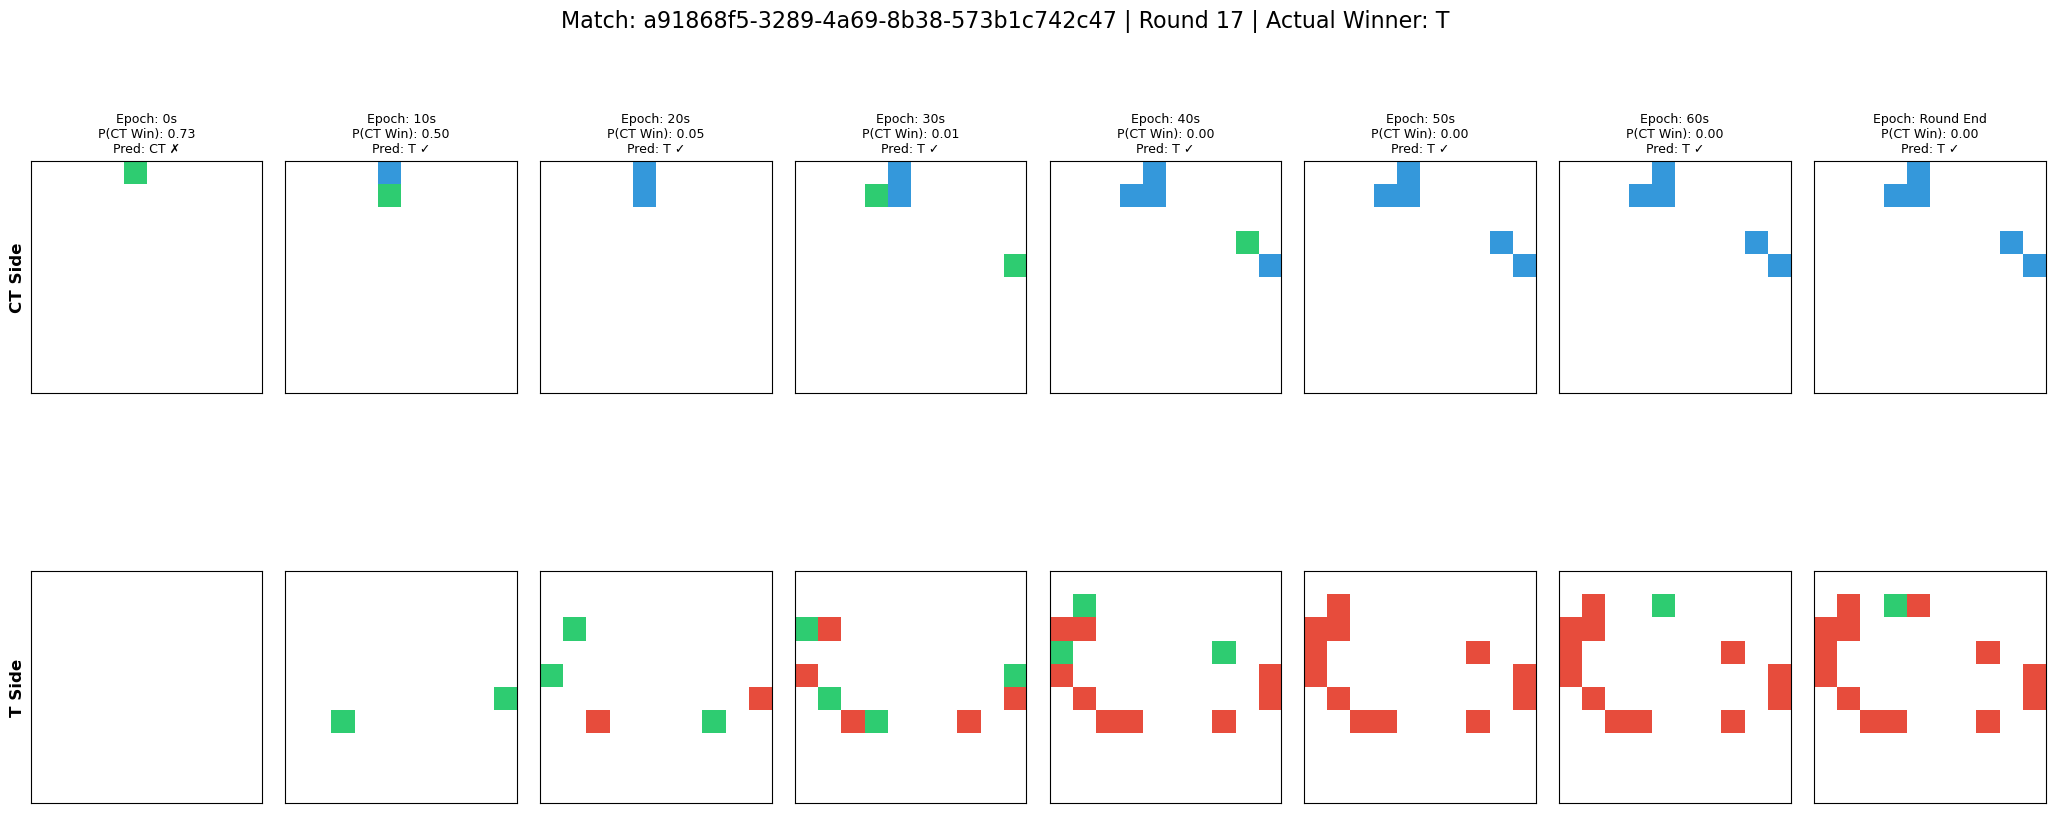

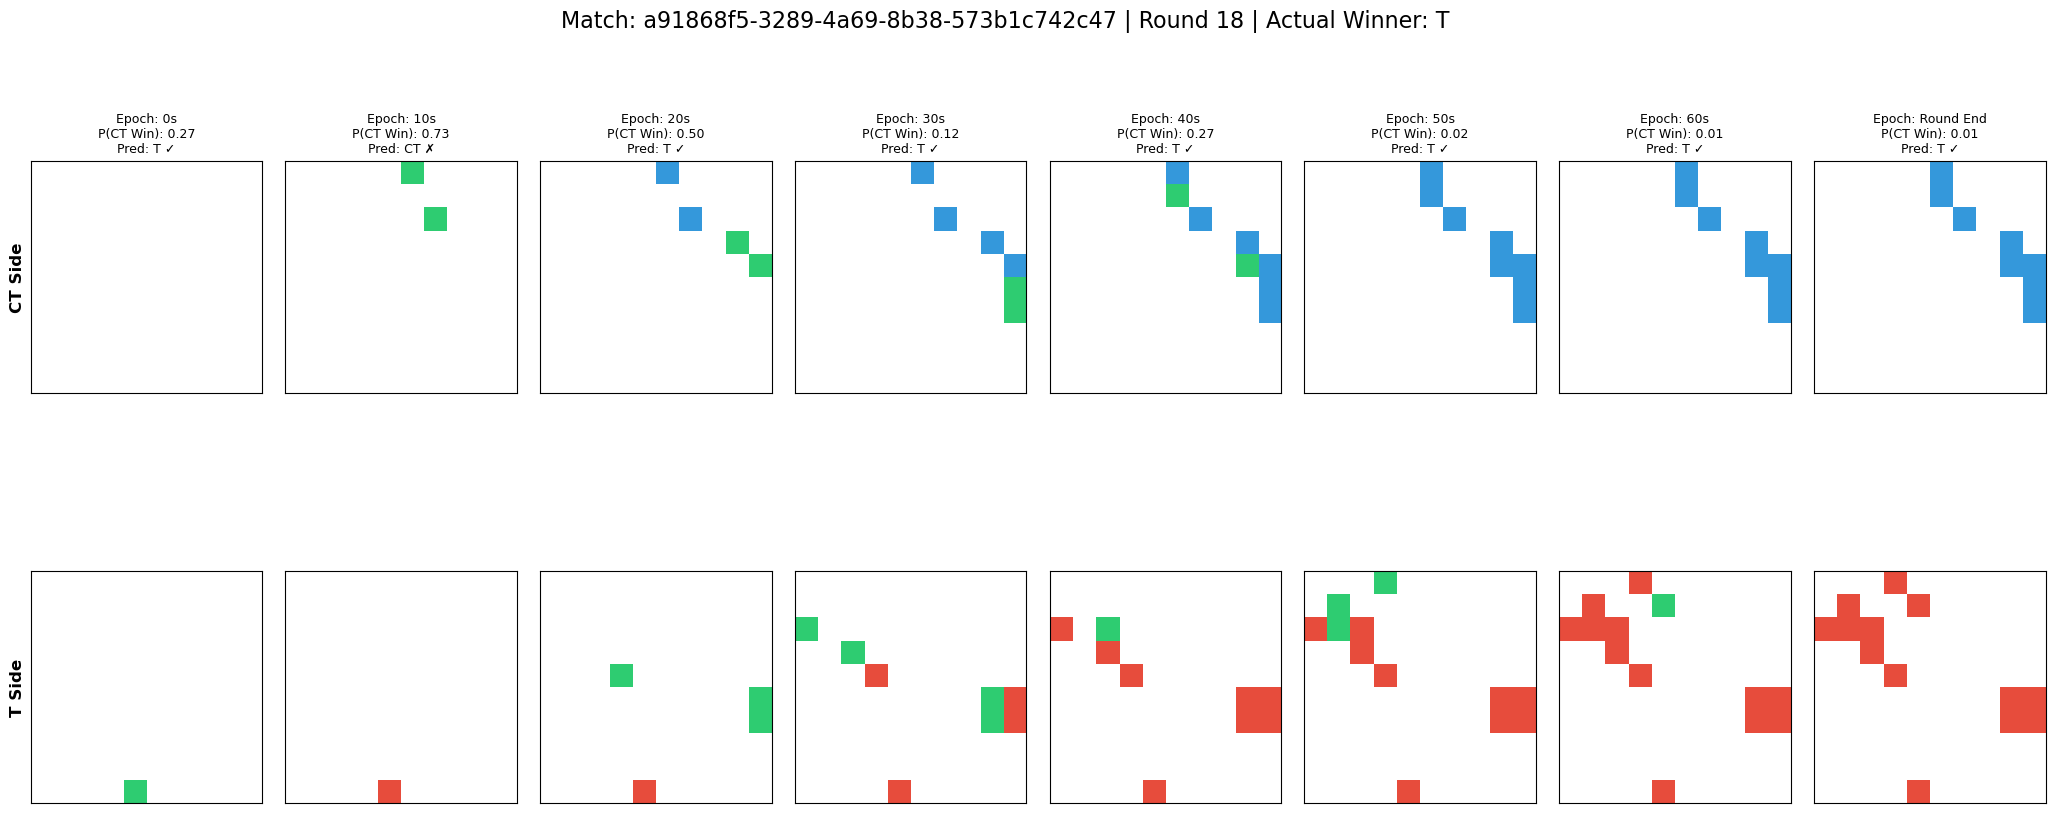

In [1]:
import polars as pl
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from pathlib import Path
import glob

# ==========================================
# 1. CONFIGURATION & CONSTANTS
# ==========================================
DATA_DIR = Path(r"D:\Research_Data_Public\Esports\CSDATA\datasets\billpureskillgg\cs2-2023-11-23\versions\2\csds")
TARGET_MAPS = ["de_ancient", "ancient"]
GRID_SIZE = 10
TICK_RATE = 64
EPOCHS_SEC = [0, 10, 20, 30, 40, 50, 60, None] 

# Fixed Ancient bounds to ensure 10x10 consistency
MAP_BOUNDS = {'x_min':  -2266.97, 'x_max' :    1395.97, 'y_min' :   -2530.58, 'y_max' :    1771.97}

#MAP_BOUNDS = { 'x_min' :   -2163.60, 'x_max' :    1787.97, 'y_min' :   -1163.97, 'y_max' :    3077.69}

def sigmoid(x):
    return 1 / (1 + np.exp(-x))

def get_parquet_path(match_dir, channel):
    """Glob-based finder for files without needing explicit extensions."""
    pattern = str(match_dir / f"{channel}*")
    files = glob.glob(pattern)
    return Path(files[0]) if files else None

# ==========================================
# 2. MATCH DISCOVERY (USING YOUR LOGIC)
# ==========================================
def extract_match_data():
    # Locate unique match directories containing a 'header' file
    match_dirs = list(set([h.parent for h in DATA_DIR.rglob("header*") if h.is_file()]))
    selected_match_dir, paths = None, {}

    print(f"Scanning {len(match_dirs)} directories for valid Ancient matches...")

    for match_dir in match_dirs:
        h_path = get_parquet_path(match_dir, "header")
        if not h_path: continue
        try:
            # Check if map is Ancient
            if pl.read_parquet(h_path)["map_name"][0].lower() in TARGET_MAPS:
                # Require all three channels for analysis
                paths = {c: get_parquet_path(match_dir, c) for c in ["weapon_fire", "header", "round_end"]}
                if all(paths.values()):
                    selected_match_dir = match_dir
                    print(f"Found Ancient Match: {selected_match_dir.name}")
                    break
        except: 
            continue

    if not selected_match_dir:
        print("Ancient match with required channels not found.")
        return None, None

    return selected_match_dir, paths

# ==========================================
# 3. ANALYSIS & VISUALIZATION
# ==========================================
def run_match_analysis(match_dir, paths):
    # Load Data
    df_fire = pl.read_parquet(paths["weapon_fire"])
    df_end = pl.read_parquet(paths["round_end"]).select(["round", "winner_team_code"])
    
    # Standardize Team Codes
    team_map = {"2": "T", "3": "CT", "TERRORIST": "T", "CT": "CT", "T": "T"}
    df_fire = df_fire.with_columns(
        pl.col("player_team_code").cast(pl.Utf8).replace(team_map).alias("side")
    ).filter(pl.col("side").is_in(["T", "CT"]))

    # Time relative to the start of weapon fire in each round
    df_fire = df_fire.with_columns(
        (pl.col("tick") - pl.col("tick").min().over("round")).alias("rel_tick")
    )

    # 10x10 Binning
    df_fire = df_fire.with_columns([
        ((pl.col("player_x_pos").clip(MAP_BOUNDS['x_min'], MAP_BOUNDS['x_max']) - MAP_BOUNDS['x_min']) / 
         (MAP_BOUNDS['x_max'] - MAP_BOUNDS['x_min']) * (GRID_SIZE - 0.01)).floor().cast(pl.Int32).alias("gx"),
        ((pl.col("player_y_pos").clip(MAP_BOUNDS['y_min'], MAP_BOUNDS['y_max']) - MAP_BOUNDS['y_min']) / 
         (MAP_BOUNDS['y_max'] - MAP_BOUNDS['y_min']) * (GRID_SIZE - 0.01)).floor().cast(pl.Int32).alias("gy")
    ])

    rounds = df_fire["round"].unique().sort().to_list()
    
    for r_id in rounds:
        r_data = df_fire.filter(pl.col("round") == r_id)
        
        # Get actual winner for result verification
        winner_data = df_end.filter(pl.col("round") == r_id)["winner_team_code"].to_list()
        actual_winner = team_map.get(str(winner_data[0]), "N/A") if winner_data else "N/A"

        fig, axes = plt.subplots(2, len(EPOCHS_SEC), figsize=(26, 9))
        plt.subplots_adjust(hspace=0.45, wspace=0.1)
        
        # Track history per side for the round
        history = {"CT": np.zeros((GRID_SIZE, GRID_SIZE), dtype=bool), 
                   "T": np.zeros((GRID_SIZE, GRID_SIZE), dtype=bool)}
        
        for epoch_idx, sec in enumerate(EPOCHS_SEC):
            limit = sec * TICK_RATE if sec is not None else float('inf')
            epoch_df = r_data.filter(pl.col("rel_tick") <= limit)
            
            # Probability calculation (CT-centric)
            ct_occupancy = epoch_df.filter(pl.col("side") == "CT").select(["gx", "gy"]).unique().height
            t_occupancy = epoch_df.filter(pl.col("side") == "T").select(["gx", "gy"]).unique().height
            ct_win_prob = sigmoid(ct_occupancy - t_occupancy)
            
            pred_winner = "CT" if ct_win_prob > 0.5 else "T"
            is_correct = "✓" if pred_winner == actual_winner else "✗"

            for side_idx, side in enumerate(["CT", "T"]):
                ax = axes[side_idx, epoch_idx]
                
                # Build current occupancy mask
                current_mask = np.zeros((GRID_SIZE, GRID_SIZE), dtype=bool)
                side_events = epoch_df.filter(pl.col("side") == side)
                if not side_events.is_empty():
                    for row in side_events.select(["gx", "gy"]).unique().iter_rows():
                        current_mask[row[1], row[0]] = True
                
                # Identify "New" activity (Delta)
                new_activity = current_mask & ~history[side]
                
                # Render Grid (0:None, 1:History, 2:New)
                viz_grid = np.zeros((GRID_SIZE, GRID_SIZE))
                viz_grid[history[side]] = 1
                viz_grid[new_activity] = 2
                
                team_hex = "#3498db" if side == "CT" else "#e74c3c"
                cmap = mcolors.ListedColormap(["#ffffff", team_hex, "#2ecc71"]) # Green Delta
                
                ax.imshow(viz_grid, cmap=cmap, origin='lower', vmin=0, vmax=2)
                
                # Formatting and Labeling
                ax.set_xticks([]); ax.set_yticks([])
                if side_idx == 0:
                    title_text = f"{sec}s" if sec is not None else "Round End"
                    ax.set_title(f"Epoch: {title_text}\nP(CT Win): {ct_win_prob:.2f}\nPred: {pred_winner} {is_correct}", fontsize=9)
                if epoch_idx == 0:
                    ax.set_ylabel(f"{side} Side", fontweight='bold', fontsize=12)

                history[side] = current_mask.copy()

        plt.suptitle(f"Match: {match_dir.name} | Round {r_id} | Actual Winner: {actual_winner}", fontsize=16, y=1.02)
        plt.show()

# ==========================================
# MAIN EXECUTION
# ==========================================
if __name__ == "__main__":
    match_dir, channel_paths = extract_match_data()
    if match_dir:
        run_match_analysis(match_dir, channel_paths)